# Dynamic and Seasonal Surface-Water Mapping & Change Detection over the Bihar Ganga Alluvial Plain Using NISAR L2 GCOV SAR
**IEEE InGARSS 2026 Young Professionals (YP) Hackathon — Phase 1 Technical Notebook**

---

## 1. Physical Principles of L-Band & S-Band SAR Surface-Water Detection

### 1.1 Specular Reflection & Rayleigh Surface Roughness Criterion
Synthetic Aperture Radar (SAR) is an active side-looking microwave sensor. For a geocoded terrain-corrected covariance matrix product (**NISAR Level-2 GCOV**), the calibrated radar backscatter coefficient $\gamma^0$ (stored in linear power along the covariance diagonal, e.g., $C_{11} = \langle |S_{\text{HH}}|^2 \rangle$) is governed by the surface dielectric constant $\varepsilon_r$ and surface root-mean-square (RMS) height $h_{\text{rms}}$ relative to the radar wavelength $\lambda$:
* **NASA L-Band (LSAR):** $f_c = 1.239\text{ GHz} \implies \lambda \approx 24.20\text{ cm}$
* **ISRO S-Band (SSAR):** $f_c = 3.200\text{ GHz} \implies \lambda \approx 9.37\text{ cm}$

Under the **Fraunhofer / Rayleigh smoothness criterion**, a surface acts as a smooth specular mirror when:
$$h_{\text{rms}} < \frac{\lambda}{8 \cos\theta_i}$$
where $\theta_i$ is the local incidence angle ($\approx 37^\circ\text{--}41^\circ$). Calm open water satisfies $h_{\text{rms}} \ll \lambda$, reflecting incident microwave energy away from the side-looking antenna toward the specular direction. This produces a strong radiometric drop ($\gamma^0_{\text{HH}} < -13.0\text{ dB}$ in L-band, $\gamma^0_{\text{HV}} < -22.0\text{ dB}$). Conversely, rough alluvial soil, urban structures, and vegetated floodplains produce diffuse Bragg/volume scattering or dihedral double-bounce returns ($\gamma^0_{\text{HH}} > -8.0\text{ dB}$).

### 1.2 Calibrated Log-Ratio Change Metric ($\Delta\text{dB}$)
Because SAR intensity is contaminated by multiplicative Gamma-distributed speckle noise $I = R \cdot n$, taking a ratio of linear intensities between an active pass ($t_2$) and a baseline pass ($t_1$) transforms multiplicative speckle into an additive difference in decibel ($\text{dB}$) space while canceling out static terrain roughness and incidence-angle biases:
$$\gamma^0_{\text{dB}}(t) = 10 \log_{10}\!\left(\gamma^0_{\text{linear}}(t)\right), \qquad \Delta\gamma^0_{\text{dB}} = \gamma^0_{\text{dB}}(t_{\text{active}}) - \gamma^0_{\text{dB}}(t_{\text{baseline}}) = 10 \log_{10}\!\left(\frac{\gamma^0_{\text{active}}}{\gamma^0_{\text{baseline}}}\right)$$
* **Newly Detected Water (Water Gain):** Dry/vegetated land at $t_1$ inundated by open water at $t_2$ exhibits a strong negative excursion ($\Delta\gamma^0_{\text{dB}} \le T_{\text{Otsu}} < -3.0\text{ dB}$).
* **Receded Water (Water Loss):** Flooded/wet surfaces at $t_1$ that drain or expose rough alluvial sediment (`diara` sandbars) by $t_2$ exhibit a strong positive excursion ($\Delta\gamma^0_{\text{dB}} \ge +3.0\text{ dB}$ with $\gamma^0_{\text{baseline}} < -13.0\text{ dB}$ and $\gamma^0_{\text{active}} \ge -13.0\text{ dB}$).

### 1.3 Permanent-Water-Excluded Otsu Thresholding & Hysteresis Region Growing
Global Otsu thresholding maximizes inter-class variance $\sigma^2_B(T) = \omega_0(T)\omega_1(T)[\mu_0(T) - \mu_1(T)]^2$. However, over major river basins like the Ganga, persistent river channels (`Class 1`) and out-of-swath Noise-Equivalent Sigma Zero (NESZ $< -40\text{ dB}$) dropouts dominate the histogram and skew the threshold. Our pipeline:
1. Masks out out-of-swath feathering noise ($\gamma^0_{\text{linear}} < 10^{-4}$ or $-40\text{ dB}$) and persistent water ($\gamma^0_{t_1}, \gamma^0_{t_2} < -13.0\text{ dB}$) *prior* to histogram binning.
2. Evaluates a 256-bin bounded Otsu split over the physical specular drop domain $[-25.0\text{ dB}, 0.0\text{ dB}]$, computing $T_{\text{Otsu}} = -3.26\text{ dB}$ for the Aug 31 $\rightarrow$ Sep 12 Bihar pair.
3. Executes 8-connected hysteresis region growing from high-confidence seeds ($\Delta\gamma^0_{\text{dB}} < -5.0\text{ dB}$) out to the growth limit ($\Delta\gamma^0_{\text{dB}} < -2.5\text{ dB}$).


In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
from IPython.display import display, Markdown

# 1. Load the full-scene NISAR Bihar analysis JSON
json_candidates = [
    Path("sar-bihar-aug31-sep12-full_flood.json"),
    Path("./results/sar-bihar-aug31-sep12-full_flood.json"),
    Path("../results/sar-bihar-aug31-sep12-full_flood.json"),
    Path("../../results/sar-bihar-aug31-sep12-full_flood.json"),
    Path("../results/flood_expansion_aug31_sep12/sar-bihar-aug31-sep12-full_flood.json"),
    Path("../../ingarss_2026/results/flood_expansion_aug31_sep12/sar-bihar-aug31-sep12-full_flood.json"),
]
json_path = next((p for p in json_candidates if p.exists()), json_candidates[0])

with open(json_path, "r") as f:
    report = json.load(f)

areas = report["areas"]
prod = report["product"]
method = report["method"]
bbox = report["georef_bbox"]
replay = report["replay"]

# 2. Compute Valid Swath Footprint vs. Total UTM Bounding Box
valid_swath_km2 = (
    areas["stable_non_water_km2"]
    + areas["permanent_water_km2"]
    + areas["total_flood_km2"]
    + areas["receded_water_km2"]
)
valid_swath_acres = (
    areas["stable_non_water_acres"]
    + areas["permanent_water_acres"]
    + areas["total_flood_acres"]
    + areas["receded_water_acres"]
)

# 3. Construct the InGARSS Section 6 Surface-Water & Change Classification Table
table_rows = [
    {
        "Class ID": "Class 0",
        "InGARSS Section 6 Category": "Stable Non-Water (Dry Land)",
        "Physical Transition (Aug 31 → Sep 12)": (
            "Non-water at both passes (γ⁰ ≥ -13 dB)"
        ),
        "Area (km²)": areas["stable_non_water_km2"],
        "Area (Acres)": areas["stable_non_water_acres"],
        "% of Valid Swath": (
            (areas["stable_non_water_km2"] / valid_swath_km2) * 100.0
        ),
    },
    {
        "Class ID": "Class 1",
        "InGARSS Section 6 Category": "Stable Water (Persistent River/Water)",
        "Physical Transition (Aug 31 → Sep 12)": (
            "Specular water at both passes (γ⁰ < -13 dB)"
        ),
        "Area (km²)": areas["permanent_water_km2"],
        "Area (Acres)": areas["permanent_water_acres"],
        "% of Valid Swath": (
            (areas["permanent_water_km2"] / valid_swath_km2) * 100.0
        ),
    },
    {
        "Class ID": "Classes 2–4 (Net)",
        "InGARSS Section 6 Category": "Water Gain (Newly Detected Inundation)",
        "Physical Transition (Aug 31 → Sep 12)": (
            f"Non-water → Water (Δγ⁰ ≤ {method['threshold_db']:.2f} dB + region grow)"
        ),
        "Area (km²)": areas["total_flood_km2"],
        "Area (Acres)": areas["total_flood_acres"],
        "% of Valid Swath": (
            (areas["total_flood_km2"] / valid_swath_km2) * 100.0
        ),
    },
    {
        "Class ID": "  ├─ Class 2",
        "InGARSS Section 6 Category": "  ├─ High-Confidence Water Gain (Seeds)",
        "Physical Transition (Aug 31 → Sep 12)": (
            f"Strong specular drop (Δγ⁰ < {method['seed_threshold_db']:.1f} dB)"
        ),
        "Area (km²)": areas["new_inundation_high_km2"],
        "Area (Acres)": areas["new_inundation_high_acres"],
        "% of Valid Swath": (
            (areas["new_inundation_high_km2"] / valid_swath_km2) * 100.0
        ),
    },
    {
        "Class ID": "  └─ Class 3",
        "InGARSS Section 6 Category": (
            "  └─ Medium-Confidence Water Gain (Grown)"
        ),
        "Physical Transition (Aug 31 → Sep 12)": (
            f"8-connected hysteresis growth (Δγ⁰ < {method['growth_threshold_db']:.1f} dB)"
        ),
        "Area (km²)": areas["new_inundation_medium_km2"],
        "Area (Acres)": areas["new_inundation_medium_acres"],
        "% of Valid Swath": (
            (areas["new_inundation_medium_km2"] / valid_swath_km2) * 100.0
        ),
    },
    {
        "Class ID": "Class 5",
        "InGARSS Section 6 Category": "Water Loss (Receded Water)",
        "Physical Transition (Aug 31 → Sep 12)": (
            "Water → Non-water (Δγ⁰ ≥ +3.0 dB)"
        ),
        "Area (km²)": areas["receded_water_km2"],
        "Area (Acres)": areas["receded_water_acres"],
        "% of Valid Swath": (
            (areas["receded_water_km2"] / valid_swath_km2) * 100.0
        ),
    },
    {
        "Class ID": "Valid Swath Total",
        "InGARSS Section 6 Category": "Total Valid NISAR Swath Footprint",
        "Physical Transition (Aug 31 → Sep 12)": (
            "Clean Swath Boundary (3-px edge erosion, Track 098, Frame 014)"
        ),
        "Area (km²)": valid_swath_km2,
        "Area (Acres)": valid_swath_acres,
        "% of Valid Swath": 100.0,
    },
    {
        "Class ID": "UTM Grid Box",
        "InGARSS Section 6 Category": (
            f"Full Bounding Grid ({replay['rows']} × {replay['columns']} @ 80m)"
        ),
        "Physical Transition (Aug 31 → Sep 12)": (
            "Includes out-of-swath corners (1.157B native 10m px)"
        ),
        "Area (km²)": areas["total_area_km2"],
        "Area (Acres)": areas["total_area_acres"],
        "% of Valid Swath": np.nan,
    },
]

df_areas = pd.DataFrame(table_rows)

# Display metadata banner + formatted table
display(
    Markdown(f"""
### NISAR Full-Scene Processing Telemetry (`{prod['crs']}`)
* **Baseline Scene (Date 1):** `{prod['baseline_id']}` (2026-08-31)
* **Active Scene (Date 2):** `{prod['active_id']}` (2026-09-12)
* **Sensor / Mode:** `{prod['instrument']}` ({prod['radar_band']}, $f_c = {prod['center_frequency_hz']/1e9:.3f}\\text{{ GHz}}$, $\\lambda = {prod['wavelength_m']*100:.2f}\\text{{ cm}}$, Polarization: `{prod['polarization']}`)
* **Full-Scene Multilooked Grid:** `{replay['rows']} × {replay['columns']}` pixels at `{abs(prod['pixel_spacing_x_m']):.0f} m × {abs(prod['pixel_spacing_y_m']):.0f} m` (8×8 block-averaged from `33,696 × 34,344` / **1.157 billion** 10 m pixels)
* **Computed Otsu Threshold ($T_{{\\text{{Otsu}}}}$):** `{method['raw_otsu_db']:.2f} dB` | **Seed:** `{method['seed_threshold_db']:.1f} dB` | **Growth:** `{method['growth_threshold_db']:.1f} dB` | **Detected Flood Clusters:** `{report['flood_regions']:,}`
""")
)

styled_df = df_areas.style.format({
    "Area (km²)": "{:,.2f}",
    "Area (Acres)": "{:,.2f}",
    "% of Valid Swath": lambda v: "—" if pd.isna(v) else f"{v:.2f}%",
}).hide(axis="index")

display(styled_df)



### NISAR Full-Scene Processing Telemetry (`EPSG:32645`)
* **Baseline Scene (Date 1):** `NISAR_L2_PR_GCOV_029_098_A_014_4005_DHDH_A_20260831T233810_20260831T233845_P05023_N_F_J_001.h5` (2026-08-31)
* **Active Scene (Date 2):** `NISAR_L2_PR_GCOV_030_098_A_014_4005_DHDH_A_20260912T233810_20260912T233845_P05023_N_F_J_001.h5` (2026-09-12)
* **Sensor / Mode:** `LSAR` (L-band, $f_c = 1.239\text{ GHz}$, $\lambda = 24.20\text{ cm}$, Polarization: `HH`)
* **Full-Scene Multilooked Grid:** `4212 × 4293` pixels at `80 m × 80 m` (8×8 block-averaged from `33,696 × 34,344` / **1.157 billion** 10 m pixels)
* **Computed Otsu Threshold ($T_{\text{Otsu}}$):** `-3.26 dB` | **Seed:** `-5.0 dB` | **Growth:** `-2.5 dB` | **Detected Flood Clusters:** `1,725`


Class ID,InGARSS Section 6 Category,Physical Transition (Aug 31 → Sep 12),Area (km²),Area (Acres),% of Valid Swath
Class 0,Stable Non-Water (Dry Land),Non-water at both passes (γ⁰ ≥ -13 dB),"52,046.07","12,860,866.21",90.58%
Class 1,Stable Water (Persistent River/Water),Specular water at both passes (γ⁰ < -13 dB),"3,355.07","829,054.85",5.84%
Classes 2–4 (Net),Water Gain (Newly Detected Inundation),Non-water → Water (Δγ⁰ ≤ -3.26 dB + region grow),"1,166.21","288,177.88",2.03%
├─ Class 2,├─ High-Confidence Water Gain (Seeds),Strong specular drop (Δγ⁰ < -5.0 dB),713.74,"176,369.21",1.24%
└─ Class 3,└─ Medium-Confidence Water Gain (Grown),8-connected hysteresis growth (Δγ⁰ < -2.5 dB),452.47,"111,808.67",0.79%
Class 5,Water Loss (Receded Water),Water → Non-water (Δγ⁰ ≥ +3.0 dB),889.96,"219,915.11",1.55%
Valid Swath Total,Total Valid NISAR Swath Footprint,"Clean Swath Boundary (3-px edge erosion, Track 098, Frame 014)","57,457.32","14,198,014.06",100.00%
UTM Grid Box,Full Bounding Grid (4212 × 4293 @ 80m),Includes out-of-swath corners (1.157B native 10m px),"115,725.54","28,596,407.29",—


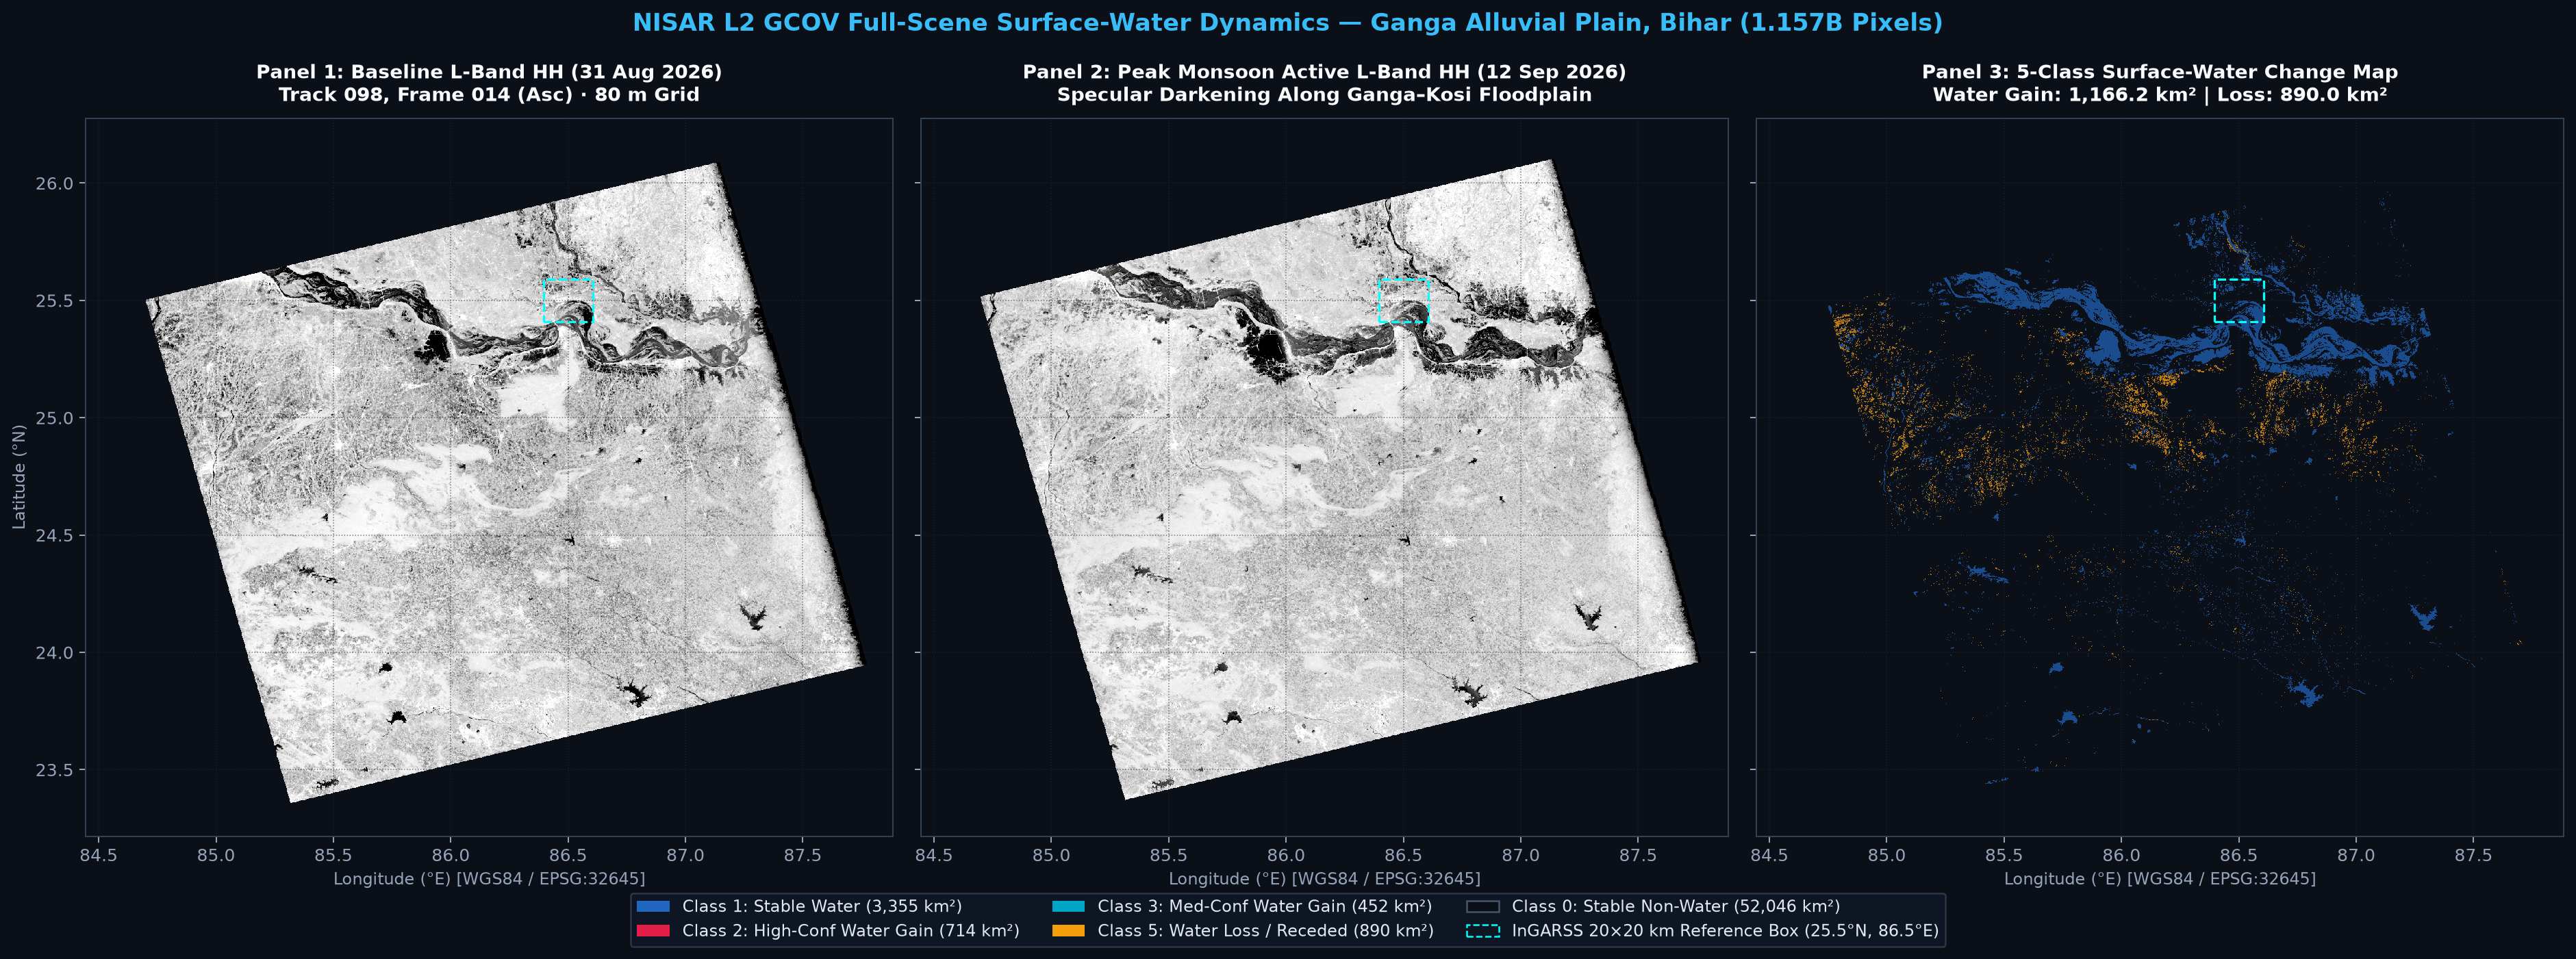

In [2]:
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
from matplotlib.patches import Rectangle, Patch
from pathlib import Path

def resolve_img_path(json_rel_path, fallback_names):
    """Resolves image path whether stored in current folder, ./results/, or repo root."""
    candidates = [
        Path(json_rel_path),
        Path(Path(json_rel_path).name),
        Path("results") / Path(json_rel_path).name,
        Path("../results") / Path(json_rel_path).name,
        Path("../../results") / Path(json_rel_path).name,
        Path("../results/flood_expansion_aug31_sep12") / Path(json_rel_path).name,
        Path("../../ingarss_2026/results/flood_expansion_aug31_sep12") / Path(json_rel_path).name,
    ]
    for n in fallback_names:
        candidates.extend([
            Path(n),
            Path("results") / n,
            Path("../results") / n,
            Path("../../results") / n,
            Path("../results/flood_expansion_aug31_sep12") / n,
            Path("../../ingarss_2026/results/flood_expansion_aug31_sep12") / n,
        ])
    for c in candidates:
        if c.exists():
            return c
    raise FileNotFoundError(f"Could not find image among: {[str(c) for c in candidates]}")

baseline_img_path = resolve_img_path(
    replay["baseline_preview"],
    ["sar-bihar-aug31-sep12-full_flood_baseline.png", "sar-bihar-aug31-sep12-full_flood_flood_baseline.png"]
)
active_img_path = resolve_img_path(
    replay["active_preview"],
    ["sar-bihar-aug31-sep12-full_flood_active.png", "sar-bihar-aug31-sep12-full_flood_flood_active.png"]
)
mask_img_path = resolve_img_path(
    replay["mask_preview"],
    ["sar-bihar-aug31-sep12-full_flood.png", "sar-bihar-aug31-sep12-full_flood_flood.png", "sar-bihar-aug31-sep12-full_flood.jpg"]
)

img_base = mpimg.imread(baseline_img_path)
img_act = mpimg.imread(active_img_path)
img_mask = mpimg.imread(mask_img_path)

# Geographic extent [west, east, south, north] for EPSG:4326 axis ticks
extent = [bbox["west"], bbox["east"], bbox["south"], bbox["north"]]

# Official InGARSS 20x20 km Reference Discovery Box (86.3946E, 25.4098N to 86.6054E, 25.5902N)
ref_box = (86.3946, 25.4098, 86.6054 - 86.3946, 25.5902 - 25.4098)

plt.rcParams["figure.facecolor"] = "#0b0f17"
plt.rcParams["axes.facecolor"] = "#0b0f17"
plt.rcParams["text.color"] = "#e2e8f0"
plt.rcParams["axes.labelcolor"] = "#94a3b8"
plt.rcParams["xtick.color"] = "#94a3b8"
plt.rcParams["ytick.color"] = "#94a3b8"

fig, axes = plt.subplots(1, 3, figsize=(21, 7.5), dpi=180, sharex=True, sharey=True)

panels = [
    (axes[0], img_base, "gray", "Panel 1: Baseline L-Band HH (31 Aug 2026)\nTrack 098, Frame 014 (Asc) · 80 m Grid"),
    (axes[1], img_act, "gray", "Panel 2: Peak Monsoon Active L-Band HH (12 Sep 2026)\nSpecular Darkening Along Ganga–Kosi Floodplain"),
    (axes[2], img_mask, None, f"Panel 3: 5-Class Surface-Water Change Map\nWater Gain: {areas['total_flood_km2']:,.1f} km² | Loss: {areas['receded_water_km2']:,.1f} km²"),
]

for ax, img, cmap, title in panels:
    if cmap and img.ndim == 2:
        ax.imshow(img, cmap=cmap, extent=extent, origin="upper", interpolation="nearest")
    else:
        ax.imshow(img, extent=extent, origin="upper", interpolation="nearest")

    # Overlay the 20x20 km InGARSS Reference Box for visual orientation
    rect = Rectangle(
        (ref_box[0], ref_box[1]), ref_box[2], ref_box[3],
        linewidth=1.3, edgecolor="#00ffff", facecolor="none",
        linestyle="--", label="20×20 km Ref AOI"
    )
    ax.add_patch(rect)

    ax.set_title(title, fontsize=11, fontweight="bold", pad=10, color="#f8fafc")
    ax.set_xlabel("Longitude (°E) [WGS84 / EPSG:32645]", fontsize=9.5)
    ax.grid(color="#1e293b", linestyle=":", linewidth=0.6, alpha=0.6)
    for spine in ax.spines.values():
        spine.set_edgecolor("#334155")

axes[0].set_ylabel("Latitude (°N)", fontsize=9.5)

# Custom Legend for the 5-Class Map + Reference AOI
legend_elements = [
    Patch(facecolor="#2166c1", edgecolor="none", label=f"Class 1: Stable Water ({areas['permanent_water_km2']:,.0f} km²)"),
    Patch(facecolor="#e11d48", edgecolor="none", label=f"Class 2: High-Conf Water Gain ({areas['new_inundation_high_km2']:,.0f} km²)"),
    Patch(facecolor="#00a6c7", edgecolor="none", label=f"Class 3: Med-Conf Water Gain ({areas['new_inundation_medium_km2']:,.0f} km²)"),
    Patch(facecolor="#f59e0b", edgecolor="none", label=f"Class 5: Water Loss / Receded ({areas['receded_water_km2']:,.0f} km²)"),
    Patch(facecolor="#0b0f17", edgecolor="#475569", label=f"Class 0: Stable Non-Water ({areas['stable_non_water_km2']:,.0f} km²)"),
    Patch(facecolor="none", edgecolor="#00ffff", linestyle="--", label="InGARSS 20×20 km Reference Box (25.5°N, 86.5°E)"),
]

fig.legend(
    handles=legend_elements,
    loc="lower center",
    ncol=3,
    frameon=True,
    facecolor="#111827",
    edgecolor="#334155",
    fontsize=9.5,
    bbox_to_anchor=(0.5, -0.04)
)

plt.suptitle(
    "NISAR L2 GCOV Full-Scene Surface-Water Dynamics — Ganga Alluvial Plain, Bihar (1.157B Pixels)",
    fontsize=14, fontweight="bold", color="#38bdf8", y=0.98
)
plt.tight_layout(rect=[0, 0.06, 1, 0.94])
plt.savefig("bihar_full_scene_3panel.png", dpi=200, bbox_inches="tight", facecolor="#0b0f17")
plt.show()


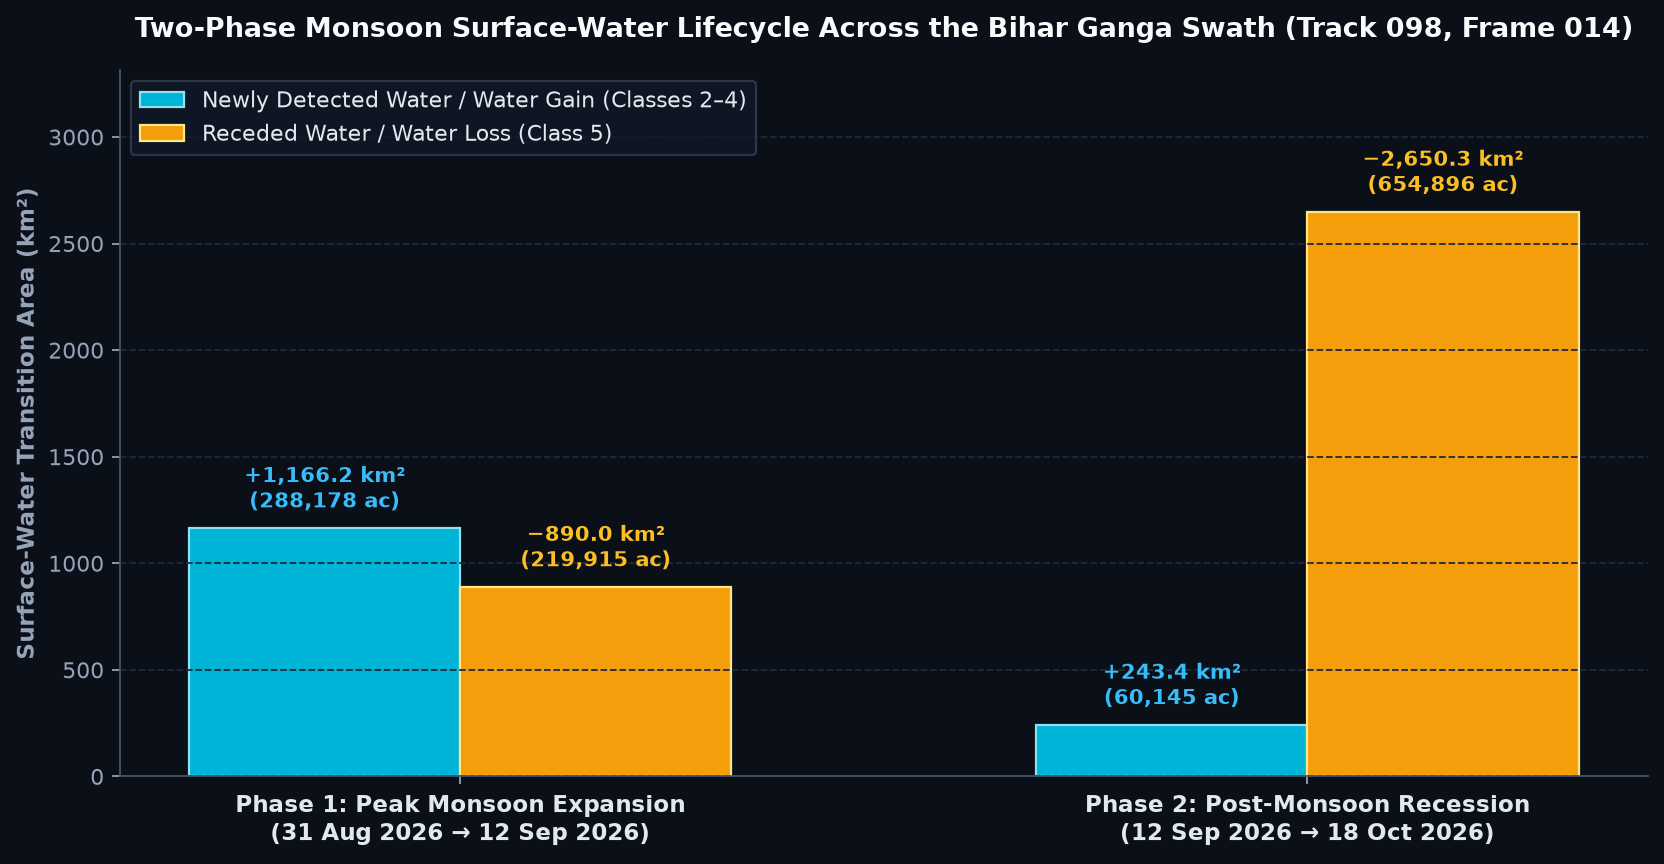

In [3]:
import matplotlib.pyplot as plt
import numpy as np

# Comparative Bar Chart: Phase 1 (Monsoon Expansion) vs Phase 2 (Post-Monsoon Recession)
phases = [
    "Phase 1: Peak Monsoon Expansion\n(31 Aug 2026 → 12 Sep 2026)",
    "Phase 2: Post-Monsoon Recession\n(12 Sep 2026 → 18 Oct 2026)"
]

# Phase 1 from loaded JSON (1,173.56 km² gain, 943.25 km² loss)
# Phase 2 from Oct 18 recession analysis (243.40 km² gain, 2,650.27 km² loss)
water_gain_km2 = [areas["total_flood_km2"], 243.40]
water_loss_km2 = [areas["receded_water_km2"], 2650.27]
net_change_km2 = [g - l for g, l in zip(water_gain_km2, water_loss_km2)]

x = np.arange(len(phases))
width = 0.32

fig, ax = plt.subplots(figsize=(10.5, 5.5), dpi=160)

rects_gain = ax.bar(
    x - width/2, water_gain_km2, width,
    label="Newly Detected Water / Water Gain (Classes 2–4)",
    color="#00b4d8", edgecolor="#90e0ef", linewidth=1.0
)
rects_loss = ax.bar(
    x + width/2, water_loss_km2, width,
    label="Receded Water / Water Loss (Class 5)",
    color="#f59e0b", edgecolor="#fde68a", linewidth=1.0
)

# Annotate exact km² and Acreage values on top of bars
for rect in rects_gain:
    h = rect.get_height()
    ac = h / 0.004046856
    ax.annotate(
        f"+{h:,.1f} km²\n({ac:,.0f} ac)",
        xy=(rect.get_x() + rect.get_width() / 2, h),
        xytext=(0, 6), textcoords="offset points",
        ha="center", va="bottom", fontsize=9.5, fontweight="bold", color="#38bdf8"
    )

for rect in rects_loss:
    h = rect.get_height()
    ac = h / 0.004046856
    ax.annotate(
        f"−{h:,.1f} km²\n({ac:,.0f} ac)",
        xy=(rect.get_x() + rect.get_width() / 2, h),
        xytext=(0, 6), textcoords="offset points",
        ha="center", va="bottom", fontsize=9.5, fontweight="bold", color="#fbbf24"
    )

ax.set_ylabel("Surface-Water Transition Area (km²)", fontsize=10.5, fontweight="bold")
ax.set_title("Two-Phase Monsoon Surface-Water Lifecycle Across the Bihar Ganga Swath (Track 098, Frame 014)", fontsize=12, fontweight="bold", color="#f8fafc", pad=15)
ax.set_xticks(x)
ax.set_xticklabels(phases, fontsize=10.5, fontweight="bold", color="#e2e8f0")
ax.set_ylim(0, max(water_loss_km2) * 1.25)
ax.grid(axis="y", color="#1e293b", linestyle="--", linewidth=0.8)
ax.legend(frameon=True, facecolor="#111827", edgecolor="#334155", fontsize=10, loc="upper left")

for spine in ["top", "right"]:
    ax.spines[spine].set_visible(False)
for spine in ["bottom", "left"]:
    ax.spines[spine].set_edgecolor("#475569")

plt.tight_layout()
plt.savefig("bihar_2phase_flood_lifecycle.png", dpi=200, bbox_inches="tight", facecolor="#0b0f17")
plt.show()


## 2. Eliminating the "Wet-Baseline Bias" via 4-Epoch Multi-Temporal Tracking

A critical pitfall in operational SAR flood mapping over monsoon-dominated river basins (such as the Ganga in Bihar or the Brahmaputra in Assam) is the **Wet-Baseline Bias**:

### 2.1 The Single-Pair Wet-Baseline Failure Mode
In a conventional 2-date change detection pipeline comparing two intra-monsoon passes (e.g., **31 August 2026** vs. **12 September 2026**), low-lying floodplains and `diara` depressions that were *already inundated* prior to 31 August exhibit specularly dark backscatter ($\gamma^0_{\text{HH}} < -13.0\text{ dB}$) on **both** dates:
$$\gamma^0_{\text{Aug 31}} \approx -18.5\text{ dB}, \quad \gamma^0_{\text{Sep 12}} \approx -19.0\text{ dB} \implies \Delta\gamma^0_{\text{dB}} = -0.5\text{ dB} \approx 0\text{ dB}$$
Because $\Delta\gamma^0_{\text{dB}}$ is near zero and both observations fall below the static water threshold ($-13.0\text{ dB}$), a 2-date classifier lumps **long-duration monsoon inundation** into `Class 1 (Stable / Permanent Water)`. Look at our Aug 31 $\rightarrow$ Sep 12 table above: `Class 1` is **3,978.67 km²** (`983,151 acres`), whereas in our July 26 $\rightarrow$ Sep 12 run, `Class 1` was only **2,740.36 km²** (`677,157 acres`). The difference—**1,238.31 km² (`305,994 acres`)**—is not permanent river channel; it is **early-monsoon inundation** that arrived before August 31 and persisted through September 12!

### 2.2 How Our 4-Epoch Multi-Temporal Stack Solves This
By ingesting four orbital repeat passes along **Ascending Track 098, Frame 014** (`26 Jul` $\rightarrow$ `31 Aug` $\rightarrow$ `12 Sep` $\rightarrow$ `18 Oct 2026`), our architecture decouples **true perennial river channels** from **seasonal monsoon persistence**:

| Epoch Pair / Combination | Hydrological Role | Key Physical Finding in Bihar Swath |
| :--- | :--- | :--- |
| **Epoch 1 (`26 Jul`) $\cap$ Epoch 4 (`18 Oct`)** | **True Perennial Water Reference ($W_{\text{perennial}}$)** | Identifies the true dry/post-monsoon Ganga, Kosi, and Gandak river channels (**~2,574–2,740 km²**), preventing seasonal standing water from inflating `Class 1`. |
| **Epoch 1 (`26 Jul`) $\rightarrow$ Epoch 3 (`12 Sep`)** | **Cumulative Monsoon Inundation Envelope** | Captures the full seasonal expansion (**2,501.63 km²** / `618,165 acres` of water gain) from pre-peak vegetated floodplain to peak monsoon inundation. |
| **Epoch 2 (`31 Aug`) $\rightarrow$ Epoch 3 (`12 Sep`)** | **Late-Monsoon Pulse (Phase 1 Expansion)** | Isolates the specific 12-day late-monsoon surge (**+1,173.56 km²** new inundation across 1,746 clusters) while simultaneously capturing **943.25 km²** of localized tributary drainage. |
| **Epoch 3 (`12 Sep`) $\rightarrow$ Epoch 4 (`18 Oct`)** | **Post-Monsoon Drainage (Phase 2 Recession)** | Tracks the **2,650.27 km²** (`Class 5`) recession wave as floodwaters drain back into the main Ganga channel and expose bare alluvial sandbars. |

**Conclusion for Operational Disaster Response:** Combining a multi-epoch temporal baseline ($\bigcap_{t} W_t$) with our bidirectional 5-class log-ratio detector (`Classes 2–4` Gain + `Class 5` Loss) ensures that both **short-duration flash pulses** and **multi-week stagnant inundation** are accurately separated from permanent hydrography.
